# 02 — Building timestamps for each flight

**Question:** can we reconstruct full local timestamps (including arrival date) for every operated flight?

**Hypothesis:** the arrival time we derive from scheduled departure + scheduled elapsed time + time-zone offset must match the reported arrival time (`arr_hhmm`), which we do not use in the calculation.

In [1]:
from pathlib import Path

import duckdb
import pandas as pd

ROOT = Path.cwd().parent
PARQUET = ROOT / "data" / "parquet" / "*.parquet"

con = duckdb.connect()
con.execute(f"CREATE VIEW flights AS SELECT * FROM read_parquet('{PARQUET.as_posix()}')")

In [2]:
con.execute("""
CREATE OR REPLACE VIEW ops AS
WITH base AS (
    -- Operated flights only, with minutes since midnight for the scheduled times
    SELECT
        tail_number, carrier, flight_number, origin, dest, flight_date,
        crs_elapsed, dep_delay, arr_delay, arr_hhmm,
        (CAST(crs_dep_hhmm AS INTEGER) // 100) * 60 + CAST(crs_dep_hhmm AS INTEGER) % 100 AS crs_dep_tod,
        (CAST(crs_arr_hhmm AS INTEGER) // 100) * 60 + CAST(crs_arr_hhmm AS INTEGER) % 100 AS crs_arr_tod
    FROM flights
    WHERE NOT cancelled AND NOT diverted AND tail_number IS NOT NULL
),
tz AS (
    -- Time-zone difference (dest - origin), recovered from the data itself:
    -- scheduled arrival clock time - (scheduled departure clock time + scheduled elapsed time)
    SELECT *,
        ((crs_arr_tod % 1440 - crs_dep_tod % 1440 - crs_elapsed) % 1440 + 1440) % 1440 AS tz_raw
    FROM base
),
tz_signed AS (
    SELECT *, CASE WHEN tz_raw >= 720 THEN tz_raw - 1440 ELSE tz_raw END AS tz_offset_min
    FROM tz
)
SELECT
    tail_number, carrier, flight_number, origin, dest, flight_date, tz_offset_min, arr_hhmm,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod)                                           AS crs_dep_ts,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod + dep_delay)                               AS dep_ts,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod + crs_elapsed + tz_offset_min)             AS crs_arr_ts,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod + crs_elapsed + tz_offset_min + arr_delay) AS arr_ts,
    dep_delay, arr_delay, crs_elapsed
FROM tz_signed
""")

con.sql("SELECT count(*) AS n_operated_flights FROM ops").df()

,n_operated_flights
0,601570


In [3]:
con.sql("""
    SELECT tz_offset_min / 60 AS tz_hours, count(*) AS n_flights
    FROM ops
    GROUP BY 1
    ORDER BY 1
""").df()

,tz_hours,n_flights
0,-6.000000,113
1,-5.000000,189
2,-4.000000,260
3,-3.000000,23158
4,-2.000000,31211
5,-1.000000,94027
6,0.000000,303559
7,0.166667,1
8,0.666667,1
9,1.000000,94089


In [4]:
con.sql("""
    SELECT
        count(*) AS n_checked,
        sum((((hour(arr_ts) * 60 + minute(arr_ts))
              - ((CAST(arr_hhmm AS INTEGER) // 100) * 60 + CAST(arr_hhmm AS INTEGER) % 100)) % 1440 <> 0)::INT) AS n_mismatch
    FROM ops
""").df()

,n_checked,n_mismatch
0,601570,1.0


**Findings**
- Reconstructed arrival time matches the reported arrival time in 601,569 of 601,570 operated flights.
- Time-zone offsets recovered from the data are whole hours between -6 and +6, except 2 flights (10 and 40 min), most likely errors in the scheduled elapsed time. These will be excluded.
- Timestamps are local to each airport. This is enough to measure turnarounds: the previous arrival and the next departure of an aircraft happen at the same airport, so both use the same clock.

## Chaining flights into aircraft rotations

**Hypothesis:** consecutive flights of the same aircraft are geographically continuous (previous destination = next origin) in the vast majority of cases.

In [5]:
con.execute("""
CREATE OR REPLACE VIEW legs AS
SELECT *,
    LAG(carrier)       OVER w AS prev_carrier,
    LAG(flight_number) OVER w AS prev_flight_number,
    LAG(dest)          OVER w AS prev_dest,
    LAG(crs_arr_ts)    OVER w AS prev_crs_arr_ts,
    LAG(arr_ts)        OVER w AS prev_arr_ts,
    LAG(arr_delay)     OVER w AS prev_arr_delay
FROM ops
WHERE tz_offset_min % 60 = 0
WINDOW w AS (PARTITION BY tail_number ORDER BY crs_dep_ts, flight_number)
""")

In [6]:
con.sql("""
    SELECT
        count(*)                                      AS n_legs,
        sum((prev_dest IS NULL)::INT)                 AS n_first_of_aircraft,
        sum((prev_dest = origin)::INT)                AS n_continuous,
        sum((prev_dest <> origin)::INT)               AS n_broken,
        round(100.0 * sum((prev_dest = origin)::INT)
              / sum((prev_dest IS NOT NULL)::INT), 2) AS pct_continuous
    FROM legs
""").df().T

,0
n_legs,601568.00
n_first_of_aircraft,5680.00
n_continuous,585577.00
n_broken,10311.00
pct_continuous,98.27


In [7]:
con.sql("""
    SELECT
        sum((prev_crs_arr_ts > crs_dep_ts)::INT) AS n_negative_scheduled_turn,
        sum((prev_arr_ts > dep_ts)::INT)         AS n_negative_actual_turn
    FROM legs
    WHERE prev_dest = origin
""").df()

,n_negative_scheduled_turn,n_negative_actual_turn
0,5296.0,218.0


**Findings**
- 98.27% of consecutive flight pairs of the same aircraft are geographically continuous (585,577 of 595,888). Tail numbers reliably identify aircraft.
- 10,311 pairs (1.7%) are broken (previous destination ≠ next origin), probably legs missing from the BTS data. Excluded from propagation analysis.
- 5,296 continuous pairs have a negative *scheduled* turnaround, most likely aircraft swaps after the schedule was built: no scheduled buffer can be measured. Excluded.
- 218 continuous pairs have a negative *actual* turnaround (data errors). Excluded.
- Rotation dataset = continuous pairs with non-negative scheduled and actual turnaround.

## Where does a rotation chain end?

**Hypothesis:** ground times are bimodal (same-day turnarounds vs. overnight stays), and the share of delay passed from one flight to the next falls as ground time grows. The cut-off should sit in the valley between the two modes.

In [8]:
con.execute("""
CREATE OR REPLACE VIEW rot AS
SELECT *,
    date_diff('minute', prev_crs_arr_ts, crs_dep_ts) AS sched_turn_min,
    date_diff('minute', prev_arr_ts, dep_ts)         AS actual_turn_min
FROM legs
WHERE prev_dest = origin
  AND prev_crs_arr_ts <= crs_dep_ts
  AND prev_arr_ts <= dep_ts
""")

con.sql("SELECT count(*) AS n_rotation_pairs FROM rot").df()

,n_rotation_pairs
0,580201


In [16]:
import logging

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # silence missing-font warnings

BRAND = {"black": "#0D0D0D", "yellow": "#F5C518", "white": "#FFFFFF", "grey": "#8C8C8C", "grid": "#262626"}
TITLE_FONT = ["Space Grotesk", "Inter 18pt", "DejaVu Sans"]

plt.rcParams.update({
    "figure.facecolor": BRAND["black"], "axes.facecolor": BRAND["black"], "savefig.facecolor": BRAND["black"],
    "axes.edgecolor": BRAND["grid"], "axes.labelcolor": BRAND["grey"],
    "xtick.color": BRAND["grey"], "ytick.color": BRAND["grey"], "text.color": BRAND["white"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": BRAND["grid"], "grid.linewidth": 1,
    "axes.axisbelow": True,
        "font.family": "sans-serif", "font.sans-serif": ["Inter 18pt", "DejaVu Sans"],
})

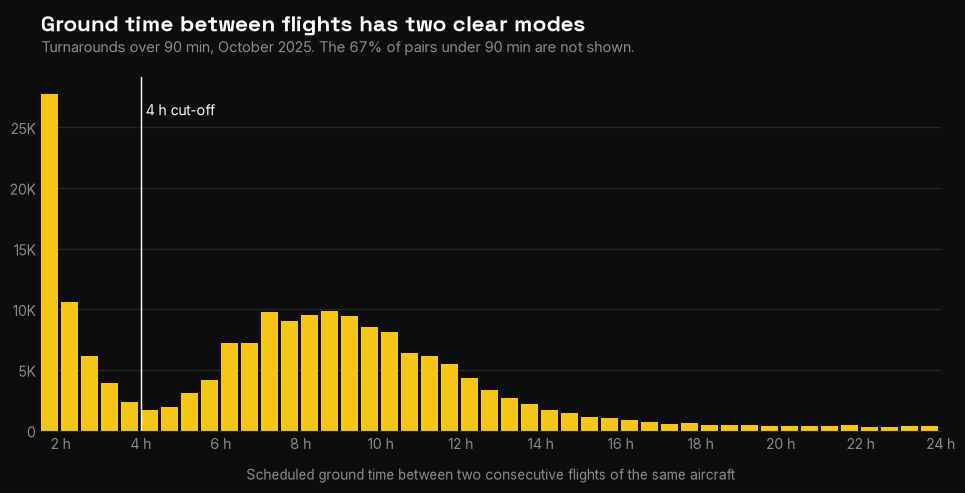

In [17]:
hist = con.sql("""
    SELECT (sched_turn_min // 30) * 30 AS bin_start_min, count(*) AS n_pairs
    FROM rot
    WHERE sched_turn_min >= 90 AND sched_turn_min < 1440
    GROUP BY 1
    ORDER BY 1
""").df()
short_share = con.sql("SELECT round(100.0 * avg((sched_turn_min < 90)::INT), 0) FROM rot").fetchone()[0]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.bar(hist["bin_start_min"] / 60, hist["n_pairs"], width=0.44, align="edge", color=BRAND["yellow"])
ax.axvline(4, color=BRAND["white"], linewidth=1)
ax.text(4.12, ax.get_ylim()[1] * 0.93, "4 h cut-off", color=BRAND["white"], fontsize=10, va="top")

ax.set_xlim(1.5, 24)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} h"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}K" if v else "0"))
ax.tick_params(length=0)
ax.set_xlabel("Scheduled ground time between two consecutive flights of the same aircraft", labelpad=10)

fig.text(0.07, 0.95, "Ground time between flights has two clear modes", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.895, f"Turnarounds over 90 min, October 2025. The {short_share:.0f}% of pairs under 90 min are not shown.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.07, right=0.97, top=0.82, bottom=0.14)

fig.savefig(ROOT / "figures" / "turnaround_distribution.png", dpi=150)
plt.show()

In [11]:
con.sql("""
    SELECT
        CASE WHEN sched_turn_min < 60  THEN '1) 0-60 min'
             WHEN sched_turn_min < 120 THEN '2) 60-120 min'
             WHEN sched_turn_min < 180 THEN '3) 2-3 h'
             WHEN sched_turn_min < 240 THEN '4) 3-4 h'
             WHEN sched_turn_min < 360 THEN '5) 4-6 h'
             WHEN sched_turn_min < 600 THEN '6) 6-10 h'
             ELSE '7) 10 h+' END                         AS turn_band,
        count(*)                                         AS n_pairs,
        round(regr_slope(dep_delay, prev_arr_delay), 3)  AS slope
    FROM rot
    GROUP BY 1
    ORDER BY 1
""").df()

,turn_band,n_pairs,slope
0,1) 0-60 min,244906,0.904
1,2) 60-120 min,171791,0.688
2,3) 2-3 h,16716,0.374
3,4) 3-4 h,6331,0.261
4,5) 4-6 h,10935,0.199
5,6) 6-10 h,70635,0.116
6,7) 10 h+,58887,0.041


**Findings**
- Scheduled ground time is bimodal: same-day turnarounds (mostly under 3 h) and overnight stays (mostly 6–12 h), with a valley around 4–5 h.
- The share of delay passed on to the next flight falls steadily with ground time: 0.90 (under 1 h), 0.69 (1–2 h), 0.37 (2–3 h), 0.26 (3–4 h), 0.20 (4–6 h), 0.12 (6–10 h), 0.04 (10 h+). There is no sharp break, only a gradual decay.
- Decision: pairs with a scheduled ground time of up to 4 h are treated as the same-day rotation chain, where propagation is analysed. Longer gaps are kept as a comparison group.
- Caveat: the slope measures association, not pure causality. Shared causes (weather or congestion at the same airport) also link both delays. The long-gap pairs give a rough idea of this baseline.